# Evaluación Parcial N°2: Machine Learning
## Inteligencia Musical y Predicción de Popularidad de Canciones (Spotify Tracks)
|Campo|Detalle|
|---|---|
|Integrantes| Catalina Villegas y Javiera Fuenzalida|
|Sección| 002D|
|Asignatura| Machine Learning|
|Docente| Ignacio Meza|

### **Metodología CRISP-DM**
El proyecto se desarrolla bajo el estándar CRISP-DM (*Cross-Industry Standard Process for Data Mining*):
1. **Comprensión del Negocio:** Definición de objetivos para estimar la popularidad y optimizar decisiones de difusión musical.
2. **Comprensión de los Datos:** Exploración del dataset Spotify Tracks (125 géneros y atributos de audio).
3. **Preparación de los Datos:** Limpieza de duplicados, tratamiento de valores nulos, acotamiento de outliers y codificación.
4. **Modelado:** Selección e implementación de algoritmos de regresión/clasificación.
5. **Evaluación:** Validación técnica de métricas predictivas frente a KPIs de negocio.
6. **Despliegue:** Documentación reproducible en formato Notebook (`.ipynb`) y Markdown (`.md`).

### **Fuentes de Datos y Herramientas Utilizadas**
* **Fuente de Datos:** Dataset `Spotify_Tracks_Dataset.csv` de Spotify con ~114,000 canciones y 20 variables (metadatos y variables acústicas como `danceability`, `energy`, `loudness`, `valence`, etc. Sin contar `unnamed`).
* **Google Colab / Jupyter:** Entorno colaborativo en la nube que garantiza ejecución reproducible del código.
* **Pandas & NumPy:** Procesamiento estructurado, limpieza y manipulación eficiente de matrices.
* **Matplotlib & Seaborn:** Generación de gráficos exploratorios para detección de patrones y sesgos.

###**Contexto y Descripción del problema de negocio**

Las plataformas de streaming musical operan en un entorno altamente dinámico donde miles de canciones son lanzadas diariamente. Para discográficas, creadores de contenido y la propia plataforma, anticipar el nivel de adopción o popularidad de un track permite optimizar la inversión en marketing, definir listas de reproducción editoriales y maximizar el engagement de la audiencia. Este proyecto aborda la necesidad de identificar qué características acústicas y metadatos influyen directamente en la popularidad de una pista musical en Spotify.

El dataset entregado contiene información sobre las pistas de Spotify alrededor de 125 géneros, además de contener información y especificaciones sobre los audios y su metadata.

###**Objetivos del Proyecto**

El objetivo general es desarrollar una solución analítica de Machine Learning para predecir la popularidad de las canciones en Spotify a partir de sus atributos acústicos y metadatos.

* Implementar el pipeline completo de ciencia de datos bajo la metodología CRISP-DM.

* Analizar y preparar el conjunto de datos resolviendo problemas de duplicados, valores faltantes y sesgos de distribución.

* Identificar los factores acústicos clave (p. ej., danceability, energy, valence) correlacionados con el éxito comercial de una canción.

### **KPIs Principales del Negocio**

**Tasa Global de Hits**

Porcentaje del catálogo con `popularity >= 70`.

**Popularidad Promedio Por género**

Identificación de géneros con mayor atractivo comercial.

**Índice de Afinidad Sonora**

Grado de correlación entre atributos acústicos clave y la popularidad.


**Duración Óptima**

Intervalo de duración (en minutos) que concentra los niveles más altos de popularidad.

##**Analizando y tratando el DataSet**

### Librerias

In [301]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os

### Carga Principal

In [302]:
df = pd.read_csv('..\data\Spotify_Tracks_Dataset_Clean.csv')
print(f'Dataset cargado: {df.shape[0]} filas x {df.shape[1]} columnas')
print('-' * 60)

print('\n1. PRIMERAS 5 FILAS (ejemplo completado):')
display(df.head())
print('-' * 60)
print(f"\n2. INFORMACIÓN:\n")
print(df.info())
print(f"\n3. ESTADÍSTICAS:\n{df.describe()}")

<>:1: SyntaxWarning: invalid escape sequence '\d'
<>:1: SyntaxWarning: invalid escape sequence '\d'
C:\Users\generica\AppData\Local\Temp\ipykernel_23104\1689561168.py:1: SyntaxWarning: invalid escape sequence '\d'
  df = pd.read_csv('..\data\Spotify_Tracks_Dataset_Clean.csv')


Dataset cargado: 113549 filas x 20 columnas
------------------------------------------------------------

1. PRIMERAS 5 FILAS (ejemplo completado):


,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4.0,acoustic
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4.0,acoustic
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4.0,acoustic
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3.0,acoustic
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4.0,acoustic


------------------------------------------------------------

2. INFORMACIÓN:

<class 'pandas.DataFrame'>
RangeIndex: 113549 entries, 0 to 113548
Data columns (total 20 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   track_id          113549 non-null  str    
 1   artists           113549 non-null  str    
 2   album_name        113549 non-null  str    
 3   track_name        113549 non-null  str    
 4   popularity        113549 non-null  int64  
 5   duration_ms       113549 non-null  int64  
 6   explicit          113549 non-null  bool   
 7   danceability      113549 non-null  float64
 8   energy            113549 non-null  float64
 9   key               113549 non-null  int64  
 10  loudness          113549 non-null  float64
 11  mode              113549 non-null  int64  
 12  speechiness       113549 non-null  float64
 13  acousticness      113549 non-null  float64
 14  instrumentalness  113549 non-null  float64
 15  

# Transformaciones

In [303]:
df['duration_min'] = df['duration_ms'] / 60000
UMBRAL_HIT = 70

df['is_hit'] = (df['popularity'] >= UMBRAL_HIT).astype(int)

In [304]:
#df['artists'].unique()  -> 31437

In [305]:
#Columnas q borramos por cosas de etica y faiclitar el proceso idf

#track_id: Es un identificador único. No tiene ningún patrón matemático que ayude a predecir si una canción será popular.
#artists: El nombre del artista influye mucho en la popularidad, pero al ser miles de nombres distintos en formato texto, 
#         si los convertimos a números (usando técnicas como One-Hot Encoding) crearemos miles de columnas nuevas 
#         y el notebook se quedará sin memoria o el modelo fallará (maldición de la dimensionalidad).
#album_name: Texto libre
#track_name: Texto libre 
#duration_ms: Tenemos la duración en minutos, lo que es visualmente más comodo para nosotras para trabajar, por lo que esta variable se vuelve redundante

df.drop(columns=['track_id'], inplace=True)
df.drop(columns=['album_name'], inplace=True)
df.drop(columns=['track_name'], inplace=True)
df.drop(columns=['duration_ms'], inplace=True)

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 113549 entries, 0 to 113548
Data columns (total 18 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   artists           113549 non-null  str    
 1   popularity        113549 non-null  int64  
 2   explicit          113549 non-null  bool   
 3   danceability      113549 non-null  float64
 4   energy            113549 non-null  float64
 5   key               113549 non-null  int64  
 6   loudness          113549 non-null  float64
 7   mode              113549 non-null  int64  
 8   speechiness       113549 non-null  float64
 9   acousticness      113549 non-null  float64
 10  instrumentalness  113549 non-null  float64
 11  liveness          113549 non-null  float64
 12  valence           113549 non-null  float64
 13  tempo             113549 non-null  float64
 14  time_signature    113549 non-null  float64
 15  track_genre       113549 non-null  str    
 16  duration_min      113549 non-nu

## Codificación Variables Categoricas

In [306]:
#df['track_genre'].unique()

# Codificacion de variables categoricas
import category_encoders as ce
from category_encoders import TargetEncoder

encoder_binario = ce.BinaryEncoder(cols=['track_genre'])
encoder = TargetEncoder(cols=['artists'], smoothing=10.0)



### Normalización y estandarización 

In [307]:
import numpy as np
from sklearn.preprocessing import StandardScaler

# 1. Transformación logarítmica para corregir el sesgo asimétrico
variables_sesgadas = ['speechiness', 'acousticness', 'instrumentalness', 'liveness', 'duration_min']
for col in variables_sesgadas:
    df[col] = np.log1p(df[col])

# 2. Seleccionamos TODAS las numéricas continuas para estandarizar
# (Incluye las que acabamos de transformar y las de escala libre)
columnas_a_estandarizar = [
    'danceability', 'energy', 'loudness', 'tempo',
    'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'duration_min'
]

# 3. Aplicamos el escalador
scaler = StandardScaler()


## Ingenieria de Caracteristicas

Fueron aplicadas en el notebook anterioir (EDA). En donde se agrego la columna duration_min y is_hit. 

- Impacto Acústico: energy × loudness (canciones que no solo son ruidosas, sino que transmiten mucha fuerza).
- Ritmo Bailable: danceability × tempo (mide el dinamismo rítmico de la pista).

In [308]:
# df['acoustic_impact'] = df['energy'] * df['loudness']
# df['dance_rhythm'] = df['danceability'] * df['tempo']



# Entrenamiento

In [314]:
#Probando con predecir hit
 
X= df.drop(columns=['is_hit', 'popularity'])
y = df['is_hit']
X = encoder_binario.fit_transform(X)
X['artists_encoded'] = encoder.fit_transform(X['artists'], y)
X = X.drop(columns=['artists'])

X[columnas_a_estandarizar]= scaler.fit_transform(X[columnas_a_estandarizar])
X.info()



<class 'pandas.DataFrame'>
RangeIndex: 113549 entries, 0 to 113548
Data columns (total 22 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   explicit          113549 non-null  bool   
 1   danceability      113549 non-null  float64
 2   energy            113549 non-null  float64
 3   key               113549 non-null  int64  
 4   loudness          113549 non-null  float64
 5   mode              113549 non-null  int64  
 6   speechiness       113549 non-null  float64
 7   acousticness      113549 non-null  float64
 8   instrumentalness  113549 non-null  float64
 9   liveness          113549 non-null  float64
 10  valence           113549 non-null  float64
 11  tempo             113549 non-null  float64
 12  time_signature    113549 non-null  float64
 13  track_genre_0     113549 non-null  int64  
 14  track_genre_1     113549 non-null  int64  
 15  track_genre_2     113549 non-null  int64  
 16  track_genre_3     113549 non-nu

In [315]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Shape of X_train: {X_train.shape}")
print(f"Shape of X_test: {X_test.shape}")
print(f"Shape of y_train: {y_train.shape}")
print(f"Shape of y_test: {y_test.shape}")


Shape of X_train: (90839, 22)
Shape of X_test: (22710, 22)
Shape of y_train: (90839,)
Shape of y_test: (22710,)


### Antes de inflar datos 

Solo para mostrar el pq debemos duplicar los datos ya que el modelo se puso flojito jeje 

In [316]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.datasets import make_classification

clf = RandomForestClassifier(random_state=42)
clf.fit(X_train, y_train)
#RandomForestClassifier(X_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [317]:
from sklearn.metrics import classification_report

y_true_rf = y_test
y_pred_rf = clf.predict(X_test)

Classification Report RandomForestClassifier:
               precision    recall  f1-score   support

           0       0.98      0.99      0.99     21589
           1       0.81      0.60      0.69      1121

    accuracy                           0.97     22710
   macro avg       0.90      0.80      0.84     22710
weighted avg       0.97      0.97      0.97     22710



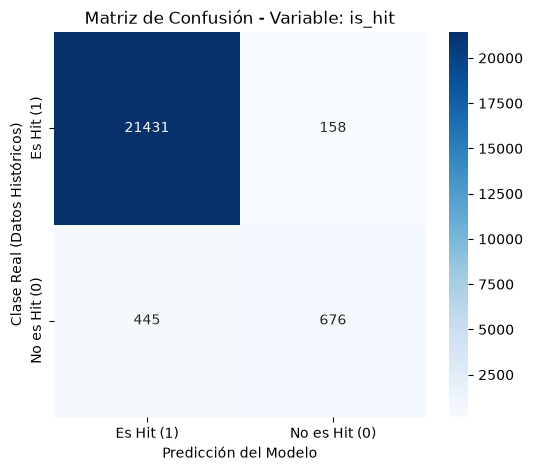

In [318]:
from sklearn.metrics import confusion_matrix, classification_report

matriz = confusion_matrix(y_true_rf, y_pred_rf)

print("Classification Report RandomForestClassifier:\n", classification_report(y_true_rf, y_pred_rf))


plt.figure(figsize=(6, 5))
sns.heatmap(
    matriz,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Es Hit (1)", "No es Hit (0)"],
    yticklabels=["Es Hit (1)", "No es Hit (0)"],
)

plt.title("Matriz de Confusión - Variable: is_hit")
plt.xlabel("Predicción del Modelo")
plt.ylabel("Clase Real (Datos Históricos)")
plt.show()

In [319]:
# 1. Cuenta cuántos 0 y 1 tienes exactamente en tu variable objetivo 'y'
# (Reemplaza 'y' por el nombre de tu variable o columna de pandas, ej: df['tu_columna'])
conteos = pd.Series(y_train).value_counts()

# Extraemos la cantidad exacta de cada uno
no_hits = conteos.get(0, 0)
hits = conteos.get(1, 0)
total = len(y_train)

# 2. Calculamos los ratios y porcentajes
porcentaje_hits = (hits / total) * 100
porcentaje_no_hits = (no_hits / total) * 100

# Evitamos división por cero en caso de que no hubiera hits
ratio_directo = no_hits / hits if hits > 0 else 0 

# 3. Imprimimos el diagnóstico en pantalla
print("=== DIAGNÓSTICO DE DESBALANCEO ===")
print(f"Total de datos analizados: {total:,}")
print(f"Clase 0 (No Hit): {no_hits:,} ({porcentaje_no_hits:.2f}%)")
print(f"Clase 1 (Hit):    {hits:,} ({porcentaje_hits:.2f}%)")
print(f"Ratio de desbalanceo: {ratio_directo:.2f}:1")

=== DIAGNÓSTICO DE DESBALANCEO ===
Total de datos analizados: 90,839
Clase 0 (No Hit): 86,492 (95.21%)
Clase 1 (Hit):    4,347 (4.79%)
Ratio de desbalanceo: 19.90:1


In [320]:
from lightgbm import LGBMClassifier

# Calculamos el ratio de desbalanceo para alimentar al modelo
# Si el 4.5% son hits, el ratio de negativos a positivos es aprox. 21 

clf_lgb = LGBMClassifier(
    scale_pos_weight=ratio_directo,
    max_depth=6,
    learning_rate=0.05,
    random_state=42,
    n_jobs=-1
)
clf_lgb.fit(X_train, y_train)


[LightGBM] [Info] Number of positive: 4347, number of negative: 86492
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.004948 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2833
[LightGBM] [Info] Number of data points in the train set: 90839, number of used features: 22
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.047854 -> initscore=-2.990566
[LightGBM] [Info] Start training from score -2.990566


,max_depth,6
,learning_rate,0.05
,random_state,42
,n_jobs,-1
,scale_pos_weight,np.float64(19.89694041867955)
,boosting_type,'gbdt'
,num_leaves,31
,n_estimators,100
,subsample_for_bin,200000
,objective,None
,class_weight,None


In [321]:
from sklearn.metrics import classification_report

y_true_lgbm = y_test
y_pred_lgbm= clf_lgb.predict(X_test)



Classification ReportLGBMClassifier:
               precision    recall  f1-score   support

           0       1.00      0.90      0.95     21589
           1       0.35      0.98      0.51      1121

    accuracy                           0.91     22710
   macro avg       0.67      0.94      0.73     22710
weighted avg       0.97      0.91      0.93     22710



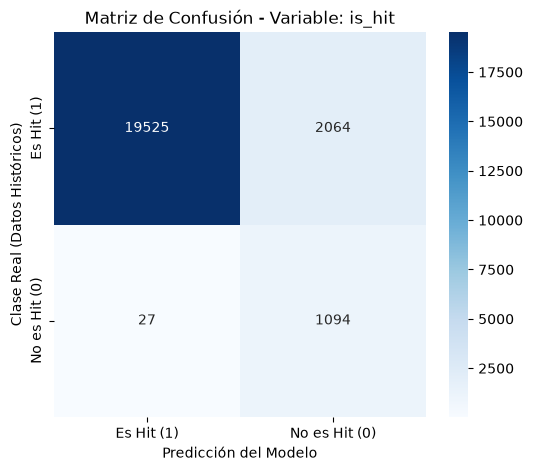

In [322]:
from sklearn.metrics import confusion_matrix, classification_report

matriz = confusion_matrix(y_true_lgbm, y_pred_lgbm)
print("Classification ReportLGBMClassifier:\n", classification_report(y_true_lgbm, y_pred_lgbm))


plt.figure(figsize=(6, 5))
sns.heatmap(
    matriz,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Es Hit (1)", "No es Hit (0)"],
    yticklabels=["Es Hit (1)", "No es Hit (0)"],
)

plt.title("Matriz de Confusión - Variable: is_hit")
plt.xlabel("Predicción del Modelo")
plt.ylabel("Clase Real (Datos Históricos)")
plt.show()

### Inflando datos ando

In [323]:
from imblearn.over_sampling import SMOTENC
from sklearn.ensemble import RandomForestClassifier


columnas_binarias = ['track_genre_0','track_genre_1','track_genre_2','track_genre_3','track_genre_4','track_genre_5','track_genre_6'] 

smote_nc = SMOTENC(categorical_features=columnas_binarias, random_state=42)
X_train_resampled, y_train_resampled = smote_nc.fit_resample(X_train, y_train)

In [324]:
from imblearn.over_sampling import SMOTENC
from sklearn.ensemble import RandomForestClassifier


columnas_binarias = ['track_genre_0','track_genre_1','track_genre_2','track_genre_3','track_genre_4','track_genre_5','track_genre_6'] 

smote_nc = SMOTENC(categorical_features=columnas_binarias, random_state=42)
X_train_resampled, y_train_resampled = smote_nc.fit_resample(X_train, y_train)

Classification Report RandomForestClassifier:
               precision    recall  f1-score   support

           0       0.99      0.97      0.98     21589
           1       0.56      0.80      0.66      1121

    accuracy                           0.96     22710
   macro avg       0.77      0.89      0.82     22710
weighted avg       0.97      0.96      0.96     22710



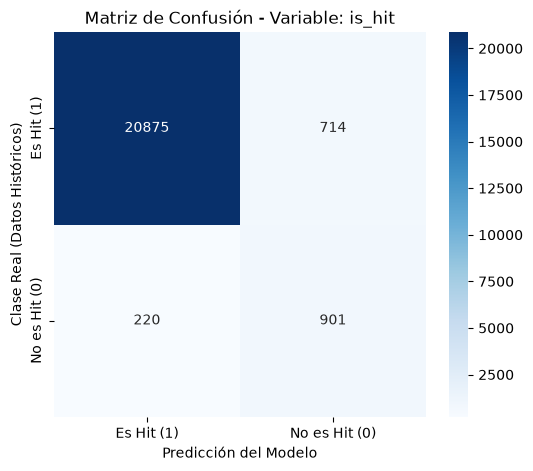

In [325]:
clf = RandomForestClassifier(random_state=42)
clf.fit(X_train_resampled, y_train_resampled)
y_true_rf = y_test
y_pred_rf = clf.predict(X_test)


matriz = confusion_matrix(y_true_rf, y_pred_rf)

print("Classification Report RandomForestClassifier:\n", classification_report(y_true_rf, y_pred_rf))


plt.figure(figsize=(6, 5))
sns.heatmap(
    matriz,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Es Hit (1)", "No es Hit (0)"],
    yticklabels=["Es Hit (1)", "No es Hit (0)"],
)

plt.title("Matriz de Confusión - Variable: is_hit")
plt.xlabel("Predicción del Modelo")
plt.ylabel("Clase Real (Datos Históricos)")
plt.show()

In [326]:
conteos = pd.Series(y_train_resampled).value_counts()

# Extraemos la cantidad exacta de cada uno
no_hits = conteos.get(0, 0)
hits = conteos.get(1, 0)
total = len(y_train_resampled)

# 2. Calculamos los ratios y porcentajes
porcentaje_hits = (hits / total) * 100
porcentaje_no_hits = (no_hits / total) * 100

# Evitamos división por cero en caso de que no hubiera hits
ratio_directo = no_hits / hits if hits > 0 else 0 

# 3. Imprimimos el diagnóstico en pantalla
print("=== DIAGNÓSTICO DE DESBALANCEO ===")
print(f"Total de datos analizados: {total:,}")
print(f"Clase 0 (No Hit): {no_hits:,} ({porcentaje_no_hits:.2f}%)")
print(f"Clase 1 (Hit):    {hits:,} ({porcentaje_hits:.2f}%)")
print(f"Ratio de desbalanceo: {ratio_directo:.2f}:1")

=== DIAGNÓSTICO DE DESBALANCEO ===
Total de datos analizados: 172,984
Clase 0 (No Hit): 86,492 (50.00%)
Clase 1 (Hit):    86,492 (50.00%)
Ratio de desbalanceo: 1.00:1


[LightGBM] [Info] Number of positive: 86492, number of negative: 86492
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.006575 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 3090
[LightGBM] [Info] Number of data points in the train set: 172984, number of used features: 22
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
Classification ReportLGBMClassifier:
               precision    recall  f1-score   support

           0       1.00      0.93      0.96     21589
           1       0.42      0.92      0.58      1121

    accuracy                           0.93     22710
   macro avg       0.71      0.93      0.77     22710
weighted avg       0.97      0.93      0.94     22710



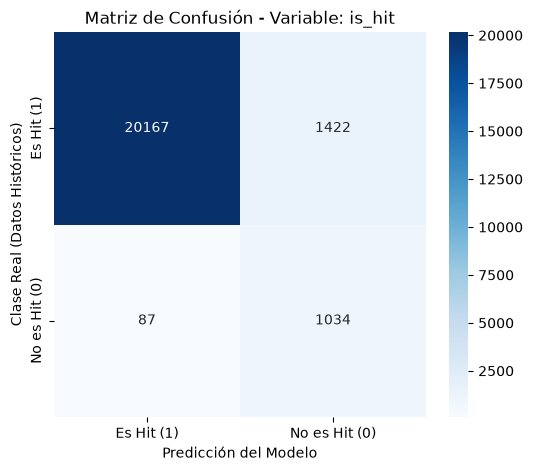

In [327]:
from lightgbm import LGBMClassifier


clf_lgb = LGBMClassifier(
    objective="binary",  
    random_state=42,
    n_estimators=200,     
    learning_rate=0.05
)

clf_lgb.fit(X_train_resampled, y_train_resampled)

y_true_lgbm = y_test
y_pred_lgbm= clf_lgb.predict(X_test)

matriz = confusion_matrix(y_true_lgbm, y_pred_lgbm)
print("Classification ReportLGBMClassifier:\n", classification_report(y_true_lgbm, y_pred_lgbm))


plt.figure(figsize=(6, 5))
sns.heatmap(
    matriz,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Es Hit (1)", "No es Hit (0)"],
    yticklabels=["Es Hit (1)", "No es Hit (0)"],
)

plt.title("Matriz de Confusión - Variable: is_hit")
plt.xlabel("Predicción del Modelo")
plt.ylabel("Clase Real (Datos Históricos)")
plt.show()

In [329]:
#Probando con predecir popularidad
 
X= df.drop(columns=['is_hit', 'popularity'])
y = df['popularity']
X = encoder_binario.fit_transform(X)
X['artists_encoded'] = encoder.fit_transform(X['artists'], y)
X = X.drop(columns=['artists'])
X[columnas_a_estandarizar]= scaler.fit_transform(X[columnas_a_estandarizar])
X.info()


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Shape of X_train: {X_train.shape}")
print(f"Shape of X_test: {X_test.shape}")
print(f"Shape of y_train: {y_train.shape}")
print(f"Shape of y_test: {y_test.shape}")

<class 'pandas.DataFrame'>
RangeIndex: 113549 entries, 0 to 113548
Data columns (total 22 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   explicit          113549 non-null  bool   
 1   danceability      113549 non-null  float64
 2   energy            113549 non-null  float64
 3   key               113549 non-null  int64  
 4   loudness          113549 non-null  float64
 5   mode              113549 non-null  int64  
 6   speechiness       113549 non-null  float64
 7   acousticness      113549 non-null  float64
 8   instrumentalness  113549 non-null  float64
 9   liveness          113549 non-null  float64
 10  valence           113549 non-null  float64
 11  tempo             113549 non-null  float64
 12  time_signature    113549 non-null  float64
 13  track_genre_0     113549 non-null  int64  
 14  track_genre_1     113549 non-null  int64  
 15  track_genre_2     113549 non-null  int64  
 16  track_genre_3     113549 non-nu

In [330]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# 1. Crear el modelo de regresión
# (max_depth evita que el modelo crezca infinitamente y tarde demasiado)
modelo_rf = RandomForestRegressor(n_estimators=200, max_depth=12, random_state=42, n_jobs=-1)

# 2. Entrenar con los datos normales (¡Aquí NO se duplica nada!)
modelo_rf.fit(X_train, y_train)

# 3. Predicciones
predicciones_rf = modelo_rf.predict(X_test)


In [331]:
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Creamos un pipeline rápido para escalar los datos y aplicar la Regresión Ridge
modelo_ridge = make_pipeline(StandardScaler(), Ridge(alpha=1.0))

# Entrenar
modelo_ridge.fit(X_train, y_train)

# Predicciones
predicciones_ridge = modelo_ridge.predict(X_test)


In [332]:
from sklearn.ensemble import HistGradientBoostingRegressor

modelo_hgb = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, random_state=42)
modelo_hgb.fit(X_train, y_train)
# Predicciones
predicciones_hgb= modelo_hgb.predict(X_test)

In [333]:
import xgboost as xgb

# Usamos Regressor en lugar de Classifier
modelo_regresion = xgb.XGBRegressor(
    objective="reg:squarederror", 
    n_estimators=600,
    learning_rate=0.04,
    max_depth=5,                  
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42
)

modelo_regresion.fit(X_train, y_train)

predicciones_regresion = modelo_regresion.predict(X_test)

In [334]:

rmse = np.sqrt(mean_squared_error(y_test, predicciones_rf))
r2 = r2_score(y_test, predicciones_rf)

rdg = np.sqrt(mean_squared_error(y_test, predicciones_ridge))
r2rdg = r2_score(y_test,  predicciones_ridge)

xgb = np.sqrt(mean_squared_error(y_test, predicciones_regresion))
rxgb = r2_score(y_test,  predicciones_regresion)

hgb = np.sqrt(mean_squared_error(y_test, predicciones_hgb))
rhgb = r2_score(y_test,  predicciones_hgb)

print(f"Error promedio (RMSE): {rmse:.2f} puntos de popularidad")
print(f"Porcentaje explicado (R² Score): {r2:.2f}")

print(f"Error promedio (Ridge): {rdg:.2f} puntos de popularidad")
print(f"Porcentaje explicado (R² Score): {r2rdg:.2f}")

print(f"Error promedio (CGB): {xgb:.2f} puntos de popularidad")
print(f"Porcentaje explicado (R² Score): {rxgb:.2f}")

print(f"Error promedio (HGB): {hgb:.2f} puntos de popularidad")
print(f"Porcentaje explicado (R² Score): {rhgb:.2f}")

Error promedio (RMSE): 12.21 puntos de popularidad
Porcentaje explicado (R² Score): 0.70
Error promedio (Ridge): 16.32 puntos de popularidad
Porcentaje explicado (R² Score): 0.47
Error promedio (CGB): 12.45 puntos de popularidad
Porcentaje explicado (R² Score): 0.69
Error promedio (HGB): 12.50 puntos de popularidad
Porcentaje explicado (R² Score): 0.69


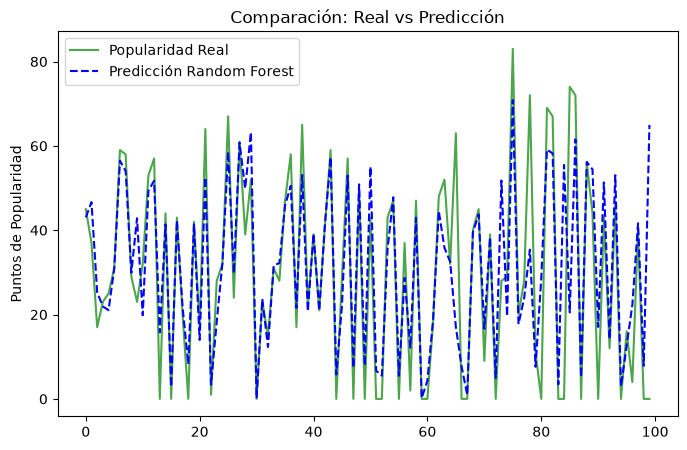

In [335]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
# Graficamos solo las primeras 100 canciones para que se entienda el gráfico visualmente
plt.plot(y_test.values[:100], label='Popularidad Real', color='green', alpha=0.7)
plt.plot(predicciones_rf[:100], label='Predicción Random Forest', color='blue', linestyle='--')
plt.title('Comparación: Real vs Predicción')
plt.ylabel('Puntos de Popularidad')
plt.legend()
plt.show()


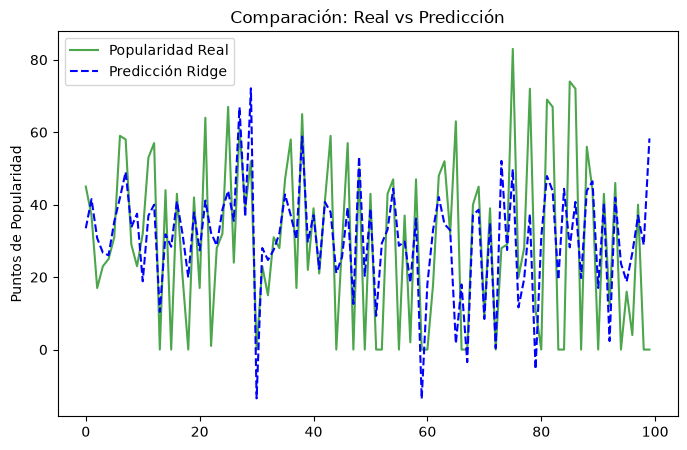

In [336]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
# Graficamos solo las primeras 100 canciones para que se entienda el gráfico visualmente
plt.plot(y_test.values[:100], label='Popularidad Real', color='green', alpha=0.7)
plt.plot(predicciones_ridge[:100], label='Predicción Ridge', color='blue', linestyle='--')
plt.title('Comparación: Real vs Predicción')
plt.ylabel('Puntos de Popularidad')
plt.legend()
plt.show()

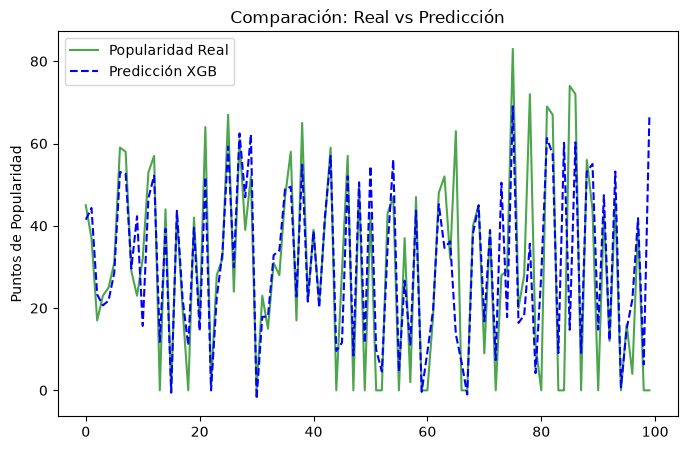

In [337]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
# Graficamos solo las primeras 100 canciones para que se entienda el gráfico visualmente
plt.plot(y_test.values[:100], label='Popularidad Real', color='green', alpha=0.7)
plt.plot(predicciones_regresion[:100], label='Predicción XGB', color='blue', linestyle='--')
plt.title('Comparación: Real vs Predicción')
plt.ylabel('Puntos de Popularidad')
plt.legend()
plt.show()

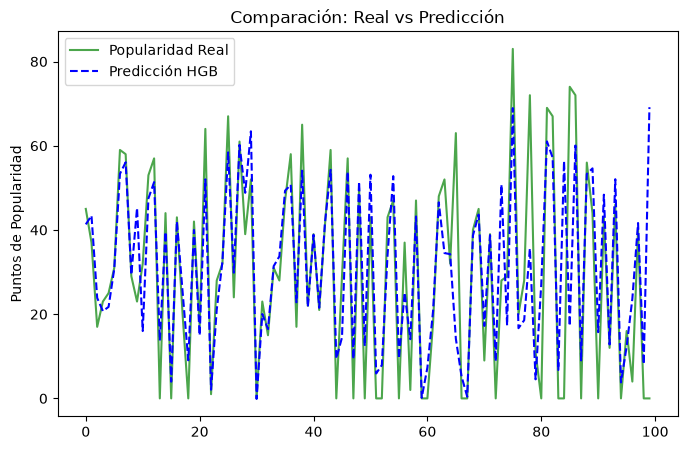

In [338]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
# Graficamos solo las primeras 100 canciones para que se entienda el gráfico visualmente
plt.plot(y_test.values[:100], label='Popularidad Real', color='green', alpha=0.7)
plt.plot(predicciones_hgb[:100], label='Predicción HGB', color='blue', linestyle='--')
plt.title('Comparación: Real vs Predicción')
plt.ylabel('Puntos de Popularidad')
plt.legend()
plt.show()